# Machine failure prediction: walkthrough

This notebook walks through the project with the committed artefacts. It re-uses the code in `src/`
(nothing is re-implemented here) and recomputes the key numbers from the stored hold-out predictions,
so every value printed below can be checked against `reports/metrics.json`.

The dataset (AI4I 2020, UCI id 601) is **synthetic**. Model outputs are screening predictions, not confirmed faults.

Run from the repository root: `jupyter notebook notebooks/walkthrough.ipynb` (Jupyter is not in `requirements.txt`).
The stored outputs were produced by executing every cell in order with Python 3.13; Jupyter itself was not available in the build environment, so the notebook has not been opened in a Jupyter kernel.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd() if (pathlib.Path.cwd() / "src").exists() else pathlib.Path.cwd().parent
sys.path.insert(0, str(ROOT))

import pandas as pd
from src import config as cfg, data, metrics, predict, recommend, plots
from src.utils import read_json

## 1. Data and validation

In [2]:
frame, report = data.load_and_validate()
print(f"{len(frame):,} rows, {int(frame[cfg.TARGET].sum())} failures ({frame[cfg.TARGET].mean():.2%})")
print("blocking errors:", len(report.errors))
for issue in report.warnings:
    print("warning:", issue.code, "-", issue.message)
print("documented rules reproduce the labels:", report.stats["documented_rule_agreement"])

10,000 rows, 339 failures (3.39%)
blocking errors: 0
documented rules reproduce the labels: {'pwf': 1.0, 'hdf': 1.0, 'osf': 1.0}


## 2. Leakage-free split and model inputs

In [3]:
train, test = data.split_dataset(frame)
X_train, y_train = data.features_and_target(train)
print("train", len(train), "failures", int(y_train.sum()), "| hold-out", len(test), "failures", int(test[cfg.TARGET].sum()))
print("model inputs:", list(X_train.columns))
print("never given to the model:", cfg.LEAKAGE_COLUMNS)

train 8000 failures 271 | hold-out 2000 failures 68
model inputs: ['type', 'air_temp_k', 'process_temp_k', 'rotational_speed_rpm', 'torque_nm', 'tool_wear_min']
never given to the model: ['machine_failure', 'twf', 'hdf', 'pwf', 'osf', 'rnf', 'udi', 'product_id']


## 3. Hold-out results of the saved model

The saved model reproduces the stored hold-out scores; metrics are recomputed from them.

In [4]:
model = predict.load_model()
holdout = predict.load_holdout_predictions()
scores = predict.score_frame(model, holdout)
stored = holdout[f"score_{model.model_key}"]
print(model.label, "| threshold", round(model.threshold, 4))
print("max |score - stored score|:", float(abs(scores - stored).max()))
m = metrics.classification_metrics(holdout[cfg.TARGET], scores, model.threshold)
print({k: round(m[k], 3) for k in ("precision", "recall", "f1", "pr_auc", "roc_auc", "mcc")})
print("TP/FP/FN/TN:", m["tp"], m["fp"], m["fn"], m["tn"])

Random forest (raw + engineered features) | threshold 0.3488
max |score - stored score|: 3.3333333329665926e-07
{'precision': 0.949, 'recall': 0.824, 'f1': 0.882, 'pr_auc': 0.891, 'roc_auc': 0.98, 'mcc': 0.88}
TP/FP/FN/TN: 56 3 12 1929


In [5]:
comparison = pd.read_csv(cfg.MODEL_COMPARISON_PATH)
comparison[["model", "cv_pr_auc_mean", "threshold", "test_precision", "test_recall", "test_f1", "test_pr_auc"]].round(3)

,model,cv_pr_auc_mean,threshold,test_precision,test_recall,test_f1,test_pr_auc
0,Baseline: majority class,0.034,0.500,0.000,0.000,0.000,0.034
1,Logistic regression (raw features),0.442,0.774,0.328,0.588,0.421,0.380
2,Random forest (raw features),0.812,0.328,0.740,0.794,0.766,0.837
3,Random forest (raw + engineered features),0.902,0.349,0.949,0.824,0.882,0.891


In [6]:
metrics.per_mode_recall(holdout, scores, model.threshold)

,mode,label,n_failures,detected,recall
0,twf,Tool wear (TWF),10,1,0.100000
1,hdf,Heat dissipation (HDF),29,28,0.965517
2,pwf,Power (PWF),13,13,1.000000
3,osf,Overstrain (OSF),16,16,1.000000
4,rnf,Random (RNF),0,0,NaN
5,no_mode_flag,Failure without a mode flag,2,0,0.000000
6,all_failures,All recorded failures,68,56,0.823529


## 4. Assessing one machine

A real hold-out record (copied unchanged) is scored and passed through the transparent rule layer.

In [7]:
row = holdout.loc[holdout["udi"] == 243].iloc[0]
reading = {c: row[c] for c in cfg.RAW_FEATURES}
result = predict.assess_reading(model, reading, holdout)
print("recorded failure in the dataset:", int(row[cfg.TARGET]))
print(result.recommendation.level.label, "-", result.recommendation.headline)
for line in result.recommendation.reasoning:
    print(" *", line)

recorded failure in the dataset: 1
High - Flag for inspection
 * Model score 0.965 vs operating threshold 0.349: at or above the operating threshold -> model level High.
 * Overstrain (tool wear x torque): ALERT - 11,878 min*Nm (alert above 11,000 min*Nm (Type L)).
 * Mechanical power: WATCH - 8,300 W (alert below 3,500 W or above 9,000 W).
 * Tool wear window: WATCH - 202 min (watch from 200 min (documented window: 200-240 min)).
 * Final level is the higher of the model level (High) and the indicator level (High) -> High.


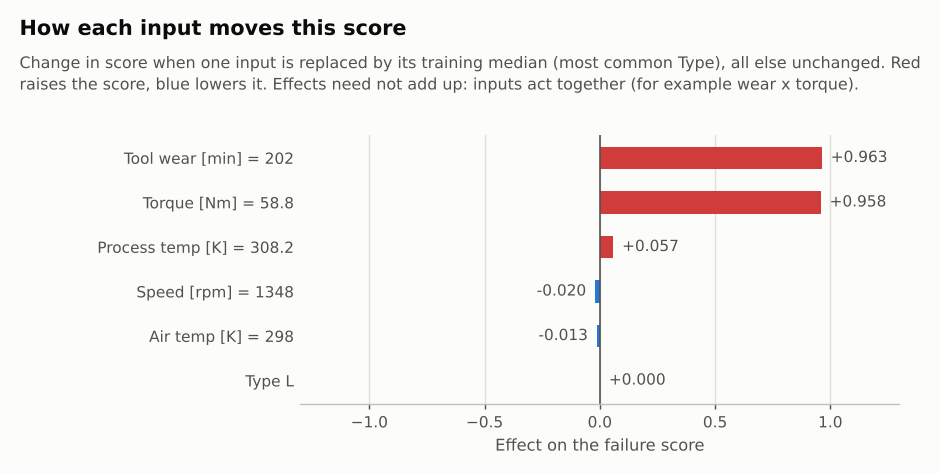

In [8]:
from IPython.display import Image
Image(plots.figure_png(plots.plot_sensitivity(result.sensitivity)))

## 5. Limitations

* Synthetic data: the labels follow documented rules plus random parts, so results show how well the
  pipeline recovers those rules, not performance on real machines.
* 68 hold-out failures: wide confidence intervals (see `reports/MODEL_CARD.md`).
* No time dimension, no sensor history; the score is not a calibrated probability.